In [4]:
pip install jupyter
jupyter notebook

SyntaxError: invalid syntax (225811081.py, line 1)

In [ ]:
import yfinance as yf
import pandas as pd

ticker = "^GDAXI"

dax = yf.download(
    ticker,
    start="2015-01-01",
    end="2026-01-01",
    interval="1d",
    auto_adjust=False
)

dax.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GDAXI,^GDAXI,^GDAXI,^GDAXI,^GDAXI,^GDAXI
Date,,,,,,
2015-01-02,9764.730469,9764.730469,9879.530273,9687.259766,9869.129883,67673900
2015-01-05,9473.160156,9473.160156,9790.269531,9468.580078,9735.650391,105538300
2015-01-06,9469.660156,9469.660156,9624.650391,9382.820312,9484.250000,96812300
2015-01-07,9518.179688,9518.179688,9592.370117,9459.179688,9510.339844,82466600
2015-01-08,9837.610352,9837.610352,9855.429688,9607.900391,9643.769531,114825000


In [ ]:
print("Dataset shape:", dax.shape)
print("\nColumns:")
print(dax.columns)

print("\nDate range:")
print(dax.index.min(), "to", dax.index.max())

print("\nMissing values:")
print(dax.isna().sum())

Dataset shape: (2790, 6)

Columns:
MultiIndex([('Adj Close', '^GDAXI'),
            (    'Close', '^GDAXI'),
            (     'High', '^GDAXI'),
            (      'Low', '^GDAXI'),
            (     'Open', '^GDAXI'),
            (   'Volume', '^GDAXI')],
           names=['Price', 'Ticker'])

Date range:
2015-01-02 00:00:00 to 2025-12-30 00:00:00

Missing values:
Price      Ticker
Adj Close  ^GDAXI    0
Close      ^GDAXI    0
High       ^GDAXI    0
Low        ^GDAXI    0
Open       ^GDAXI    0
Volume     ^GDAXI    0
dtype: int64


<Axes: xlabel='Date'>

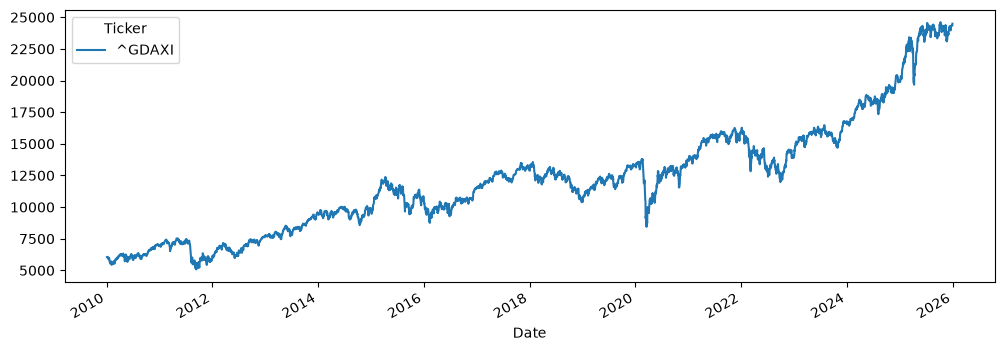

In [ ]:
dax["Close"].plot(figsize=(12, 4))

In [ ]:
print(dax.head())
print(dax.tail())
print(dax.shape)
print(dax.isna().sum())

Price         Adj Close        Close         High          Low         Open  \
Ticker           ^GDAXI       ^GDAXI       ^GDAXI       ^GDAXI       ^GDAXI   
Date                                                                          
2015-01-02  9764.730469  9764.730469  9879.530273  9687.259766  9869.129883   
2015-01-05  9473.160156  9473.160156  9790.269531  9468.580078  9735.650391   
2015-01-06  9469.660156  9469.660156  9624.650391  9382.820312  9484.250000   
2015-01-07  9518.179688  9518.179688  9592.370117  9459.179688  9510.339844   
2015-01-08  9837.610352  9837.610352  9855.429688  9607.900391  9643.769531   

Price          Volume  
Ticker         ^GDAXI  
Date                   
2015-01-02   67673900  
2015-01-05  105538300  
2015-01-06   96812300  
2015-01-07   82466600  
2015-01-08  114825000  
Price          Adj Close         Close          High           Low  \
Ticker            ^GDAXI        ^GDAXI        ^GDAXI        ^GDAXI   
Date                               

In [ ]:
dax.columns = dax.columns.get_level_values(0)

In [ ]:
(dax["Volume"] == 0).sum()

np.int64(13)

In [ ]:
dax.columns = dax.columns.get_level_values(0)
dax = dax[["Open", "High", "Low", "Close", "Volume"]]   # Adj Close equals Close for an index
dax.head(10)

Price,Open,High,Low,Close,Volume
Date,,,,,
2010-01-04,5975.520020,6048.299805,5974.430176,6048.299805,104344400
2010-01-05,6043.939941,6058.020020,6015.669922,6031.859863,117572100
2010-01-06,6032.390137,6047.569824,5997.089844,6034.330078,108742400
2010-01-07,6016.799805,6037.569824,5961.250000,6019.359863,133704300
2010-01-08,6028.620117,6053.040039,5972.240234,6037.609863,126099000
2010-01-11,6057.930176,6094.259766,6031.140137,6040.500000,103675800
2010-01-12,6039.390137,6055.560059,5924.720215,5943.000000,129269700
2010-01-13,5937.169922,5974.439941,5925.240234,5963.140137,114728400
2010-01-14,5999.080078,6009.910156,5951.689941,5988.879883,115453700


In [ ]:
print("Duplicate dates:", dax.index.duplicated().sum())
print("Sorted by date:", dax.index.is_monotonic_increasing)
print("Zero-volume days:", (dax["Volume"] == 0).sum())
print("Non-positive prices:", (dax[["Open", "High", "Low", "Close"]] <= 0).any(axis=1).sum())

bad = (dax["High"] < dax[["Open", "Close", "Low"]].max(axis=1) - 1e-6) | \
      (dax["Low"]  > dax[["Open", "Close", "High"]].min(axis=1) + 1e-6)
print("Inconsistent OHLC rows:", bad.sum())

Duplicate dates: 0
Sorted by date: True
Zero-volume days: 13
Non-positive prices: 0
Inconsistent OHLC rows: 0


In [ ]:
import numpy as np

z = dax[dax["Volume"] == 0].copy()
z["weekday"] = z.index.day_name()
z["range_%"] = 100 * np.log(z["High"] / z["Low"])
z["ret_%"] = (100 * np.log(dax["Close"] / dax["Close"].shift(1))).loc[z.index]
z[["weekday", "Open", "High", "Low", "Close", "range_%", "ret_%"]]

Price,weekday,Open,High,Low,Close,range_%,ret_%
Date,,,,,,,
2018-04-27,Friday,12572.719727,12627.709961,12518.030273,12580.870117,0.872358,0.641119
2018-07-06,Friday,12506.269531,12508.080078,12426.400391,12496.169922,0.655157,0.255443
2018-07-13,Friday,12549.230469,12583.790039,12499.299805,12540.730469,0.673685,0.381572
2018-08-10,Friday,12574.200195,12585.830078,12390.400391,12424.349609,1.564957,-2.006092
2018-09-11,Tuesday,12013.009766,12017.730469,11865.469727,11970.269531,1.275062,-0.134162
2018-09-24,Monday,12383.419922,12409.959961,12349.299805,12350.820312,0.490001,-0.646121
2018-10-10,Wednesday,11976.700195,11978.799805,11712.269531,11712.500000,2.250143,-2.234984
2018-10-25,Thursday,11098.679688,11324.919922,11078.370117,11307.120117,2.201103,1.026646
2018-11-06,Tuesday,11518.169922,11528.519531,11436.530273,11484.339844,0.801128,-0.092432


In [ ]:
gaps = dax.index.to_series().diff().dt.days
print(gaps.value_counts().sort_index())
print(gaps[gaps > 5])

Date
1.0    3204
2.0      13
3.0     787
4.0      26
5.0      24
6.0       4
Name: count, dtype: int64
Date
2012-12-27    6.0
2014-12-29    6.0
2018-12-27    6.0
2025-12-29    6.0
Name: Date, dtype: float64


In [ ]:
import numpy as np
ret = 100 * np.log(dax["Close"]).diff().dropna()   # daily log return in percent
print(ret.describe().round(3))
print(ret.abs().nlargest(5).round(2))

Ticker    ^GDAXI
count   2789.000
mean       0.033
std        1.204
min      -13.055
25%       -0.496
50%        0.079
75%        0.658
max       10.414


TypeError: DataFrame.nlargest() missing 1 required positional argument: 'columns'

In [ ]:
ret = ret.squeeze()    # one-column table -> series
print(ret.abs().nlargest(5).round(2))

Date
2020-03-12    13.05
2020-03-24    10.41
2020-03-09     8.28
2022-03-09     7.62
2016-06-24     7.07
Name: Close, dtype: float64


In [ ]:
import numpy as np
close = dax["Close"].squeeze()      # one column -> a Series
r = np.log(close).diff() * 100      # daily log return in percent
r.head(1)

Date
2015-01-02   NaN
Name: Close, dtype: float64

In [ ]:
ret = ret.squeeze()                              # one-column table -> series
top5 = ret.loc[ret.abs().nlargest(5).index]      # keep the sign
print(top5.round(2))

NameError: name 'ret' is not defined